# KAN-7 — Agregações do histórico de pedidos

Projeto CIN0144 · Tema 8: Praso — Previsão de Inadimplência.

Objetivo: transformar a tabela de pedidos (uma linha por pedido) em uma tabela de **features comportamentais por cliente**, indexada por `id_cliente`, para o modelo comportamental (KAN-8).

**Regras**
- O código fica em `src/features_comportamentais.py`. Tudo lá é determinístico e linha a linha por cliente: nada olha o alvo nem estatísticas do conjunto de clientes, então pode rodar na base inteira.
- **Todo cruzamento com o alvo usa só o treino** do split compartilhado (`src/split.py`, KAN-5). O teste fica intocado para a avaliação final.
- Os dados não têm data de referência, e o último pedido de cada cliente pode ser aquele em que a inadimplência foi observada. Por isso há duas versões das features: **(a) todos os pedidos** e **(b) sem o último pedido** (conservadora).

> Os CSVs ficam em `data/raw/` e **não vão para o GitHub** (termo de confidencialidade da Praso). Aqui aparecem só agregados, nunca linhas de clientes.

## 1. Configuração

In [1]:
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score
from sklearn.pipeline import make_pipeline

sys.path.insert(0, str(Path.cwd().parent))
from src import avaliacao as av
from src import dados
from src import features_aplicacao as fa
from src import features_comportamentais as fc
from src import split as sp

pd.set_option("display.max_columns", 60)
pd.set_option("display.float_format", "{:.3f}".format)
FIG = Path("../reports/figures")
AZUL, LARANJA = "#2a78d6", "#eb6834"  # paleta da EDA

In [2]:
clientes, pedidos = dados.carregar_dados_limpos()

# Split da KAN-5: recriado pela seed e conferido com o salvo, se existir
split = sp.criar_split(clientes, pedidos)
if sp.ARQ_SPLIT.exists():
    assert sp.carregar_split().sort_index().equals(split.sort_index()), "split salvo diferente do recriado"
else:
    sp.salvar_split(split)
conjunto = clientes["id_cliente"].map(split)
treino = clientes[conjunto == "treino"].reset_index(drop=True)
alvo_treino = treino.set_index("id_cliente")["inadimplente"]

tem_pedidos = clientes["id_cliente"].isin(pedidos["id_cliente"])
pd.DataFrame({
    "clientes": conjunto.value_counts(),
    "com pedidos": tem_pedidos.groupby(conjunto).sum(),
    "inadimplentes com pedidos": (tem_pedidos & clientes["inadimplente"].eq(1)).groupby(conjunto).sum(),
}).loc[["treino", "teste"]]

,clientes,com pedidos,inadimplentes com pedidos
id_cliente,,,
treino,2400,531,110
teste,600,133,28


**Leitura:** 531 dos 2.400 clientes do treino têm pedidos, e só 110 deles são inadimplentes. No teste são 133 com pedidos e 28 inadimplentes. Todo resultado nos clientes com pedidos tem erro padrão grande, e a seção 7 mede isso fold a fold.

## 2. Conversão das faixas

`fc.converter_pedidos` representa cada faixa pelo **ponto médio** (`_num`) e pela **posição** (`_ord`, código da categórica ordenada da limpeza). Duas exceções:
- a última faixa é aberta (`(2000, 10000000]`, `(60, 10000000]`): vale o limite inferior, porque o teto é artificial;
- atraso `(-100, 0]` significa entregue sem atraso: vale 0 (o ponto médio seria −50).

In [3]:
pc = fc.converter_pedidos(pedidos)
tabelas = []
for col in ["valor", "atraso"]:
    t = pc.groupby(col, observed=True).agg(num=(f"{col}_num", "first"), ord=(f"{col}_ord", "first"), pedidos=(col, "size"))
    t["% dos pedidos"] = t["pedidos"] / t["pedidos"].sum()
    tabelas.append(t.rename_axis("faixa").assign(coluna=col).set_index("coluna", append=True).swaplevel())
pd.concat(tabelas)

num   ord  pedidos  % dos pedidos
coluna faixa                                                  
valor  (0, 500]          250.000 0.000     1577          0.798
       (500, 1000]       750.000 1.000      278          0.141
       (1000, 2000]     1500.000 2.000       97          0.049
       (2000, 10000000] 2000.000 3.000       24          0.012
atraso (-100, 0]           0.000 0.000      543          0.275
       (0, 2]              1.000 1.000      903          0.457
       (2, 4]              3.000 2.000      255          0.129
       (4, 6]              5.000 3.000      105          0.053
       (6, 10]             8.000 4.000       74          0.037
       (10, 15]           12.500 5.000       40          0.020
       (15, 30]           22.500 6.000       28          0.014
       (30, 60]           45.000 7.000       16          0.008
       (60, 10000000]     60.000 8.000       12          0.006

**Leitura:** 80% dos pedidos estão na menor faixa de valor, então o valor varia pouco. No atraso, só 27% foram entregues sem atraso e 46% atrasaram de 1 a 2 dias. A faixa `(0, 2]` é a mais comum, e por isso `pct_atraso` (qualquer atraso) separa menos que `pct_atraso_2d` (acima de 2 dias).

## 3. Estrutura do histórico

Quantos pedidos cada cliente tem, com que ritmo, e o que fazer com os pedidos com nulo e com os pedidos repetidos no mesmo dia. Só contagens, sem o alvo.

In [4]:
por_cliente = pedidos.groupby("id_cliente").size()
ordenados = fc.ordenar_pedidos(pc)
intervalo = ordenados.groupby("id_cliente")["data_entrega"].diff().dt.days.dropna()
pd.Series({
    "pedidos": len(pedidos),
    "clientes com pedidos": por_cliente.size,
    "clientes com 3 / 2 / 1 pedidos": " / ".join(str((por_cliente == k).sum()) for k in [3, 2, 1]),
    "primeira e última data": f"{pedidos['data_entrega'].min():%m/%Y} a {pedidos['data_entrega'].max():%m/%Y}",
    "% dos pedidos em 2023": f"{(pedidos['data_entrega'].dt.year == 2023).mean():.0%}",
    "mediana de dias entre pedidos": intervalo.median(),
    "pares de pedidos no mesmo dia": int((intervalo == 0).sum()),
}, name="valor").to_frame()

,valor
pedidos,1977
clientes com pedidos,664
clientes com 3 / 2 / 1 pedidos,651 / 11 / 2
primeira e última data,04/2022 a 04/2026
% dos pedidos em 2023,77%
mediana de dias entre pedidos,15.000
pares de pedidos no mesmo dia,74


**Leitura:** 651 dos 664 clientes têm **exatamente 3 pedidos**, então isto parece um recorte com os últimos 3 pedidos de cada cliente, não o histórico completo. O volume de compras não é observável: `n_pedidos` fica no dicionário para conferência, mas não entra no modelo. As features úteis descrevem **como** foram esses pedidos (atraso, valor, ritmo). As datas vão de 2022 a 2026, mas 77% dos pedidos são de 2023.

### 3.1 Pedidos com nulo

A limpeza (KAN-1) manteve os 2 pedidos com nulo e deixou a decisão para cá. Em que posição do histórico eles estão?

In [5]:
nulos = dados.pedidos_com_nulo(ordenados)
posicao = ordenados.groupby("id_cliente").cumcount(ascending=False).map({0: "último", 1: "penúltimo", 2: "antepenúltimo"})
pd.DataFrame({
    "sem valor": ordenados.loc[nulos, "valor"].isna().groupby(posicao[nulos]).sum(),
    "sem atraso": ordenados.loc[nulos, "atraso"].isna().groupby(posicao[nulos]).sum(),
}).rename_axis("posição do pedido")

,sem valor,sem atraso
posição do pedido,,
penúltimo,1,1


**Decisão:** os 2 pedidos ficam. Os dois são o penúltimo pedido do cliente, um sem valor e outro sem atraso. A data deles vale, então contam em `n_pedidos`, nos intervalos e no span. Nas estatísticas da coluna que falta, o nulo é ignorado (a média de atraso do cliente sai dos outros 2 pedidos). Na versão (b), o pedido sem atraso vira o último do cliente, e por isso `atraso_ultimo` fica nulo para 1 cliente.

### 3.2 Pedidos repetidos no mesmo dia

Há pedidos do mesmo cliente, no mesmo dia e na mesma faixa de valor. Antes de tratá-los como duplicatas, vale ver se isso é mais do que o acaso explicaria, já que ~80% dos pedidos caem na faixa `(0, 500]`.

In [6]:
mesmo_dia = pedidos.duplicated(["id_cliente", "data_entrega"])
mesma_faixa = pedidos.duplicated(["id_cliente", "data_entrega", "valor"])
mesmo_tudo = pedidos.duplicated(["id_cliente", "data_entrega", "valor", "atraso"])
p_faixa = (pedidos["valor"].value_counts(normalize=True) ** 2).sum()  # chance de dois pedidos caírem na mesma faixa
pd.Series({
    "id_pedido repetido": int(pedidos["id_pedido"].duplicated().sum()),
    "pedidos excedentes no mesmo dia": int(mesmo_dia.sum()),
    "... e na mesma faixa de valor": int(mesma_faixa.sum()),
    "... esperado pelo acaso": round(mesmo_dia.sum() * p_faixa, 1),
    "... e também na mesma faixa de atraso": int(mesmo_tudo.sum()),
}, name="pedidos").to_frame()

,pedidos
id_pedido repetido,0.000
pedidos excedentes no mesmo dia,74.000
... e na mesma faixa de valor,54.000
... esperado pelo acaso,48.800
... e também na mesma faixa de atraso,42.000


**Decisão:** manter todos os pedidos. Nenhum `id_pedido` se repete, a coincidência de faixa de valor (54) é a esperada pelo acaso (~49), e 12 dos 54 têm atraso diferente, então não são cópias. Para quem preferir contar dias em vez de pedidos, `n_dias_com_pedido` junta os pedidos do mesmo dia.

## 4. Vazamento temporal

> **A partir daqui os cruzamentos com o alvo usam só os clientes do treino.**

### 4.1 Sinal por posição do pedido

Se o último pedido for o que gerou a inadimplência, o atraso dele deve separar o alvo muito mais do que o dos pedidos anteriores.

In [7]:
ord_treino = ordenados.join(alvo_treino, on="id_cliente", how="inner")
ord_treino["posicao"] = ord_treino.groupby("id_cliente").cumcount(ascending=False).map(
    {0: "último", 1: "penúltimo", 2: "antepenúltimo"})
ord_treino = ord_treino.dropna(subset=["posicao", "atrasou_2d"])
pos = (ord_treino.groupby(["posicao", ord_treino["atrasou_2d"].map({0: "atraso ≤ 2 dias", 1: "atraso > 2 dias"})])
       ["inadimplente"].agg(pedidos="size", taxa="mean").unstack())
pos = pos.loc[["antepenúltimo", "penúltimo", "último"]]
pos

pedidos                            taxa                
atrasou_2d    atraso > 2 dias atraso ≤ 2 dias atraso > 2 dias atraso ≤ 2 dias
posicao                                                                      
antepenúltimo             122             397           0.279           0.166
penúltimo                 147             382           0.327           0.160
último                    144             387           0.403           0.134

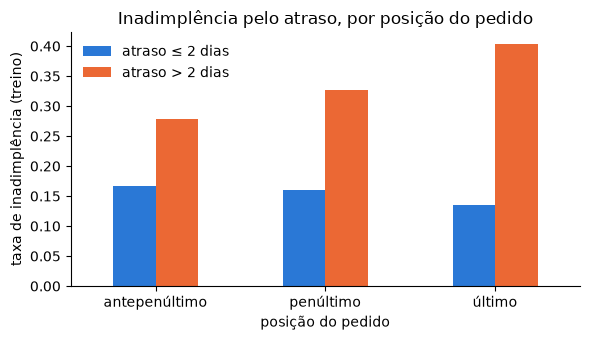

In [8]:
fig, ax = plt.subplots(figsize=(6, 3.5))
pos["taxa"][["atraso ≤ 2 dias", "atraso > 2 dias"]].plot.bar(ax=ax, rot=0, color=[AZUL, LARANJA])
ax.legend(title=None, frameon=False)
ax.set_ylabel("taxa de inadimplência (treino)")
ax.set_xlabel("posição do pedido")
ax.set_title("Inadimplência pelo atraso, por posição do pedido")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.savefig(FIG / "kan7_atraso_por_posicao.png", dpi=150); plt.show()

**Leitura:** quanto mais recente o pedido, mais o atraso separa o alvo. Entre os pedidos com atraso acima de 2 dias, a taxa de inadimplência sobe de 27,9% (antepenúltimo) para 32,7% (penúltimo) e 40,3% (último). Entre os sem atraso relevante, cai de 16,6% para 13,4%. A distância entre os dois grupos passa de 11 para 27 pontos percentuais.

Isso é o que se espera se o último pedido for, ao menos em parte, aquele em que a inadimplência aconteceu. Também pode ser só que o comportamento recente prevê melhor. Os dados não permitem separar as duas explicações, e por isso existem as duas versões.

### 4.2 Sinal pela época do último pedido

Recência absoluta (dias até uma data fixa) mediria a época em que o cliente comprou. Se a taxa varia muito com a época, a recência capturaria a época, e não o comportamento.

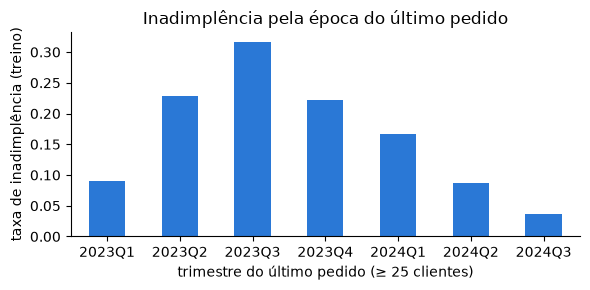

,clientes,taxa
trimestre,,
2023Q1,33,0.091
2023Q2,92,0.228
2023Q3,117,0.316
2023Q4,113,0.221
2024Q1,60,0.167
2024Q2,46,0.087
2024Q3,27,0.037


In [9]:
ultimo = ordenados.groupby("id_cliente")["data_entrega"].max()
epoca = pd.concat([ultimo.dt.to_period("Q").rename("trimestre"), alvo_treino], axis=1, join="inner")
por_epoca = epoca.groupby("trimestre")["inadimplente"].agg(clientes="size", taxa="mean")
por_epoca = por_epoca[por_epoca["clientes"] >= 25]
fig, ax = plt.subplots(figsize=(6, 3))
por_epoca["taxa"].plot.bar(ax=ax, rot=0, color=AZUL)
ax.set_ylabel("taxa de inadimplência (treino)")
ax.set_xlabel("trimestre do último pedido (≥ 25 clientes)")
ax.set_title("Inadimplência pela época do último pedido")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.savefig(FIG / "kan7_taxa_por_epoca.png", dpi=150); plt.show()
por_epoca

**Decisão:** sem recência absoluta. A taxa de inadimplência vai de 3,7% a 31,6% conforme o trimestre do último pedido, e o padrão não é monotônico (sobe até 2023T3 e depois cai). Uma feature de "dias desde o último pedido até uma data fixa" aprenderia a época, que não se repete para clientes novos. A KAN-8 fala em "clientes que compraram nos últimos 30 dias", mas sem uma data de referência esse grupo não tem definição.

## 5. Agregação por cliente e dicionário

`fc.agregar_pedidos` gera uma linha por cliente com pedidos, nas duas versões. As features são calculadas na base inteira: cada cliente só depende dos próprios pedidos (a seção 8 confere).

In [10]:
feats = {"a": fc.agregar_pedidos(pc), "b": fc.agregar_pedidos(pc, excluir_ultimo=True)}
assert all(f.index.is_unique for f in feats.values())
assert (feats["b"]["n_pedidos"] == feats["a"].loc[feats["b"].index, "n_pedidos"] - 1).all()
print({v: f.shape for v, f in feats.items()})
pd.DataFrame({"nulos (a)": feats["a"].isna().sum(), "nulos (b)": feats["b"].isna().sum()}).query("`nulos (a)` > 0 or `nulos (b)` > 0")

{'a': (664, 17), 'b': (662, 17)}


,nulos (a),nulos (b)
atraso_ultimo,0,1
atraso_tendencia,2,12
intervalo_medio_dias,2,11


**Leitura:** a versão (b) tem 662 clientes: os 2 com um pedido só ficam sem histórico. Os nulos são esperados: `atraso_tendencia` e `intervalo_medio_dias` precisam de 2 pedidos (em (b), os 11 clientes com 2 pedidos ficam com 1), e o `atraso_ultimo` nulo em (b) é o pedido sem atraso da seção 3.1.

In [11]:
pd.DataFrame.from_dict(fc.DICIONARIO, orient="index", columns=["descrição"]).rename_axis("feature")

,descrição
feature,
n_pedidos,Número de pedidos do cliente (quase sempre 3: ...
n_dias_com_pedido,Número de dias distintos com pedido (vários pe...
valor_media,Média do valor dos pedidos (ponto médio da fai...
valor_mediana,Mediana do valor dos pedidos (ponto médio da f...
valor_min,"Menor valor de pedido (ponto médio da faixa, R$)."
valor_max,"Maior valor de pedido (ponto médio da faixa, R$)."
valor_ord_max,"Maior faixa de valor (0 = (0, 500], 3 = acima ..."
atraso_media,Média do atraso em dias (sem atraso = 0; ponto...
atraso_mediana,Mediana do atraso em dias (sem atraso = 0; pon...


In [12]:
feats["a"].describe().T[["mean", "std", "min", "50%", "max"]]

,mean,std,min,50%,max
n_pedidos,2.977,0.168,1.000,3.000,3.000
n_dias_com_pedido,2.866,0.358,1.000,3.000,3.000
valor_media,402.359,281.593,250.000,250.000,2000.000
valor_mediana,378.765,309.760,250.000,250.000,2000.000
valor_min,295.181,183.787,250.000,250.000,2000.000
valor_max,533.133,466.884,250.000,250.000,2000.000
valor_ord_max,0.503,0.790,0.000,0.000,3.000
atraso_media,2.711,5.376,0.000,1.000,55.000
atraso_mediana,2.047,5.240,0.000,1.000,60.000
atraso_max,5.081,9.493,0.000,3.000,60.000


## 6. Sinal univariado: (a) vs. (b)

AUC de cada feature sozinha contra o alvo, nos clientes do treino com pedidos (0,5 = sem sinal; abaixo de 0,5 = relação inversa). Se uma feature perde muito sinal sem o último pedido, o sinal dela vinha principalmente desse pedido.

In [13]:
def auc_univariada(f):
    base = f.join(alvo_treino, how="inner")
    return pd.Series({col: roc_auc_score(base.loc[base[col].notna(), "inadimplente"], base.loc[base[col].notna(), col])
                      for col in fc.FEATURES})

auc = pd.DataFrame({"(a) todos": auc_univariada(feats["a"]), "(b) sem o último": auc_univariada(feats["b"])})
auc["diferença"] = auc["(a) todos"] - auc["(b) sem o último"]
print("clientes do treino com pedidos:", feats["a"].index.isin(alvo_treino.index).sum())
auc.sort_values("(a) todos", ascending=False)

clientes do treino com pedidos: 531


,(a) todos,(b) sem o último,diferença
atraso_ultimo,0.712,0.650,0.061
atraso_media,0.699,0.637,0.062
atraso_mediana,0.684,0.637,0.048
atraso_max,0.684,0.627,0.057
atraso_ord_max,0.684,0.627,0.057
pct_atraso_2d,0.678,0.612,0.065
atraso_tendencia,0.647,0.585,0.062
pct_atraso,0.620,0.581,0.039
valor_min,0.473,0.473,0.000
valor_mediana,0.457,0.435,0.021


**Leitura:**
- **O sinal está no atraso.** As 8 features de atraso têm AUC de 0,62 a 0,71 em (a). Sem o último pedido, perdem de 0,04 a 0,065, mas continuam com sinal (0,58 a 0,65).
- **Valor e ritmo têm relação inversa e fraca** (AUC de 0,36 a 0,47): pedidos maiores e intervalos mais longos vêm com um pouco menos de inadimplência. `intervalo_medio_dias` e `span_dias` (0,36 a 0,40) podem carregar parte do efeito de época da seção 4.2. Quase não mudam entre (a) e (b).
- `atraso_ultimo` é a feature mais forte em (a) (0,712), coerente com a seção 4.1.

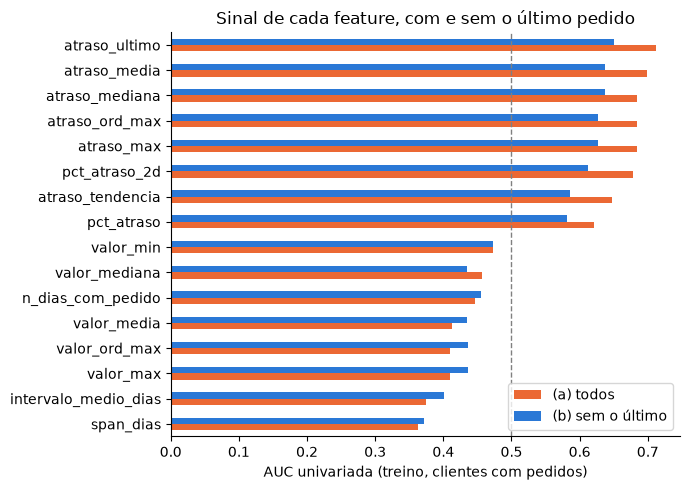

In [14]:
fig, ax = plt.subplots(figsize=(7, 5))
auc[["(a) todos", "(b) sem o último"]].sort_values("(a) todos").plot.barh(ax=ax, color=[LARANJA, AZUL])
ax.axvline(0.5, color="gray", lw=1, ls="--")
ax.set_xlabel("AUC univariada (treino, clientes com pedidos)")
ax.set_title("Sinal de cada feature, com e sem o último pedido")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.savefig(FIG / "kan7_auc_univariada.png", dpi=150); plt.show()

### 6.1 Redundância

Correlação de Spearman entre as features da versão (a), nos clientes com pedidos (sem o alvo). Pares muito correlacionados carregam a mesma informação.

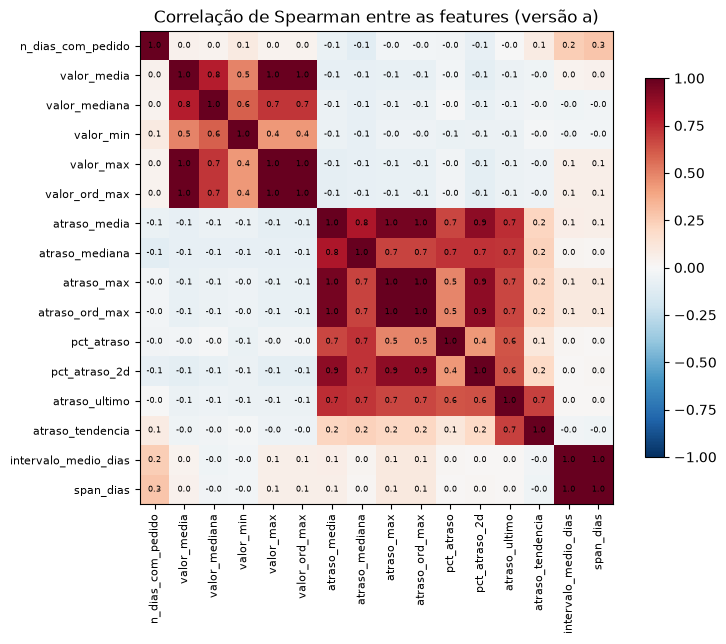

Spearman
valor_max            valor_ord_max      1.000
atraso_max           atraso_ord_max     1.000
intervalo_medio_dias span_dias          0.998
valor_media          valor_max          0.992
                     valor_ord_max      0.992
atraso_media         atraso_max         0.955
                     atraso_ord_max     0.955
atraso_max           pct_atraso_2d      0.893
atraso_ord_max       pct_atraso_2d      0.893
atraso_media         pct_atraso_2d      0.892
                     atraso_mediana     0.805

In [15]:
corr = feats["a"][fc.FEATURES].corr(method="spearman")
fig, ax = plt.subplots(figsize=(8, 6.5))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)), corr.columns, rotation=90, fontsize=8)
ax.set_yticks(range(len(corr)), corr.index, fontsize=8)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f"{corr.iloc[i, j]:.1f}", ha="center", va="center", fontsize=6)
fig.colorbar(im, ax=ax, shrink=0.8)
ax.set_title("Correlação de Spearman entre as features (versão a)")
plt.tight_layout(); plt.savefig(FIG / "kan7_correlacao.png", dpi=150); plt.show()

triang = np.triu(np.ones(corr.shape, dtype=bool), k=1)
pares = corr.where(triang).stack()
pares[pares.abs() >= 0.8].sort_values(ascending=False).rename("Spearman").to_frame()

**Leitura:** há pares que são a mesma informação: `valor_max` e `valor_ord_max` (1,00), `atraso_max` e `atraso_ord_max` (1,00), `intervalo_medio_dias` e `span_dias` (0,998) e `valor_media` e `valor_max` (0,99). Com quase todo cliente tendo 3 pedidos, o máximo e a faixa máxima têm a mesma ordem, e o span é 2× o intervalo médio. A KAN-8 pode ficar com um de cada par sem perder nada.

## 7. Quanto os pedidos acrescentam ao modelo de aplicação

A EDA e a seção 6 olham cada feature sozinha. Aqui a pergunta é a da KAN-8: **com as 10 features do modelo de aplicação (KAN-5) já no modelo, os pedidos acrescentam algo?** E quanto disso sobra **sem o último pedido**?

- Mesma Random Forest e mesmos 25 folds da KAN-5 (parâmetros fixos, sem tuning; o modelo é da KAN-8).
- O modelo é treinado em todo o treino. Quem não tem pedidos fica com as features comportamentais nulas (a Random Forest do scikit-learn aceita nulos), e "tem pedidos" não entra como feature.
- A avaliação é separada por grupo: o que interessa é o AUC **nos clientes com pedidos** (cerca de 106 por fold de validação, ~25 inadimplentes), então o erro padrão é bem maior que o da KAN-5.
- Blocos: **atraso** (média, mediana, máximo, faixa máxima, % com atraso, % acima de 2 dias, atraso do último e tendência), **valor** e **ritmo** (dias com pedido, intervalo médio, span).

In [16]:
ATRASO = ["atraso_media", "atraso_mediana", "atraso_max", "atraso_ord_max", "pct_atraso", "pct_atraso_2d",
          "atraso_ultimo", "atraso_tendencia"]
VALOR = ["valor_media", "valor_mediana", "valor_min", "valor_max", "valor_ord_max"]
RITMO = ["n_dias_com_pedido", "intervalo_medio_dias", "span_dias"]
assert sorted(ATRASO + VALOR + RITMO) == sorted(fc.FEATURES)

cv = sp.folds(treino, pedidos)
y_treino = treino["inadimplente"]
grupo = treino["id_cliente"].isin(pedidos["id_cliente"]).map({True: "com pedidos", False: "sem pedidos"})
X_apl = fa.criar_features(treino)[fa.FEATURES_FINAIS]
X_v = {v: pd.concat([X_apl, treino[["id_cliente"]].join(f, on="id_cliente")[fc.FEATURES]], axis=1) for v, f in feats.items()}
rf = RandomForestClassifier(n_estimators=300, min_samples_leaf=20, max_features="sqrt", n_jobs=-1, random_state=42)


def pipeline(comportamentais):
    """Pré-processador da KAN-5 nas features de aplicação; as comportamentais passam como estão (nulos inclusive)."""
    pre = ColumnTransformer([
        ("aplicacao", fa.montar_preprocessador(fa.FEATURES_FINAIS), fa.FEATURES_FINAIS),
        ("pedidos", "passthrough", comportamentais),
    ], verbose_feature_names_out=False).set_output(transform="pandas")
    return make_pipeline(pre, clone(rf))


configs = {
    "aplicação": ("a", []),
    **{f"+ pedidos ({v})": (v, fc.FEATURES) for v in "ab"},
    **{f"+ atraso ({v})": (v, ATRASO) for v in "ab"},
    "+ pedidos sem atraso (a)": ("a", VALOR + RITMO),
    "+ pedidos sem atraso_ultimo (a)": ("a", [c for c in fc.FEATURES if c != "atraso_ultimo"]),
}
por_grupo, inicio = {}, time.time()
for nome, (v, cols) in configs.items():
    por_grupo[nome] = av.auc_por_fold_e_grupo(pipeline(cols), X_v[v], y_treino, cv, grupo)
    print(f"{nome:<34} {time.time() - inicio:5.0f}s")
pd.DataFrame({n: g.mean() for n, g in por_grupo.items()}).T[["todos", "com pedidos", "sem pedidos"]]

aplicação                              5s


+ pedidos (a)                         10s


+ pedidos (b)                         15s


+ atraso (a)                          19s


+ atraso (b)                          24s


+ pedidos sem atraso (a)              29s


+ pedidos sem atraso_ultimo (a)       34s


,todos,com pedidos,sem pedidos
aplicação,0.772,0.692,0.788
+ pedidos (a),0.789,0.786,0.786
+ pedidos (b),0.781,0.742,0.785
+ atraso (a),0.788,0.776,0.786
+ atraso (b),0.780,0.725,0.786
+ pedidos sem atraso (a),0.780,0.717,0.787
+ pedidos sem atraso_ultimo (a),0.789,0.786,0.785


In [17]:
testes = [
    ("pedidos (a)", "+ pedidos (a)", "aplicação"),
    ("pedidos (b), sem o último", "+ pedidos (b)", "aplicação"),
    ("último pedido: (a) vs. (b)", "+ pedidos (a)", "+ pedidos (b)"),
    ("só atraso (a)", "+ atraso (a)", "aplicação"),
    ("só atraso (b)", "+ atraso (b)", "aplicação"),
    ("valor e ritmo, com o atraso já no modelo (a)", "+ pedidos (a)", "+ atraso (a)"),
    ("atraso, com valor e ritmo já no modelo (a)", "+ pedidos (a)", "+ pedidos sem atraso (a)"),
    ("atraso_ultimo, com o resto já no modelo (a)", "+ pedidos (a)", "+ pedidos sem atraso_ultimo (a)"),
]
pd.DataFrame([
    {"item": item, "avaliado em": g, **av.comparar(por_grupo[com][g], por_grupo[sem][g], cv)}
    for item, com, sem in testes for g in ["com pedidos"]
]).set_index("item")

,avaliado em,ganho,erro padrão,ganho / erro padrão,veredito
item,,,,,
pedidos (a),com pedidos,0.094,0.030,3.114,acrescenta
"pedidos (b), sem o último",com pedidos,0.050,0.023,2.150,acrescenta
último pedido: (a) vs. (b),com pedidos,0.045,0.019,2.375,acrescenta
só atraso (a),com pedidos,0.084,0.030,2.797,acrescenta
só atraso (b),com pedidos,0.033,0.020,1.622,acrescenta
"valor e ritmo, com o atraso já no modelo (a)",com pedidos,0.011,0.014,0.762,neutro
"atraso, com valor e ritmo já no modelo (a)",com pedidos,0.069,0.032,2.148,acrescenta
"atraso_ultimo, com o resto já no modelo (a)",com pedidos,0.000,0.005,0.076,neutro


**Como ler:** a primeira tabela dá o AUC médio nos 25 folds, em todo o treino e dentro de cada grupo. A segunda dá o ganho pareado **nos clientes com pedidos**, com o erro padrão corrigido e o veredito da regra da KAN-5 (acrescenta se o ganho passa de 1 erro padrão).

**Leitura:**
1. **Os pedidos acrescentam muito para quem tem pedidos.** Nesse grupo, o modelo de aplicação tem AUC 0,692 (bem abaixo dos 0,788 de quem não tem pedidos). Com os pedidos (a), sobe para 0,786: +0,094, 3,1 erros padrão.
2. **Cerca de metade do ganho vem do último pedido.** Sem ele (b), o ganho cai para +0,050 (2,2 erros padrão). A diferença entre (a) e (b) é de 0,045 (2,4 erros padrão). Se o último pedido for o da inadimplência, o ganho honesto está mais perto de +0,05 que de +0,09.
3. **O ganho vem do atraso.** Só o bloco de atraso já dá +0,084 em (a). Com o atraso no modelo, valor e ritmo não acrescentam (+0,011, neutro).
4. **Tirar só `atraso_ultimo` não protege contra o vazamento** (ganho 0,000 ao recolocá-la): a média, o máximo e as proporções de (a) já contêm o último pedido. Para a versão conservadora é preciso agregar sem ele, como faz (b).
5. Para quem não tem pedidos, nada muda (0,788 → 0,786): as features nulas não atrapalham o modelo de aplicação.

> O erro padrão é de 0,02 a 0,03, cerca de 3× o da KAN-5, porque só ~25 inadimplentes com pedidos entram em cada fold de validação. As conclusões são de direção e ordem de grandeza.

## 8. Checagens de vazamento

Conferências automáticas de que nada do alvo ou do teste entrou nas features, e de que cada cliente só depende dos próprios pedidos. Cada linha é um `assert`.

In [18]:
amostra = pedidos[pedidos["id_cliente"].isin(pedidos["id_cliente"].drop_duplicates().sample(100, random_state=0))]
teste_ids = set(clientes.loc[conjunto == "teste", "id_cliente"])
checagens = {
    "nenhuma feature tem o alvo ou id no nome": not set(fc.DICIONARIO) & {"inadimplente", "id_cliente", "id_pedido"},
    "agregar é por cliente (a): subconjunto dá o mesmo resultado":
        fc.agregar_pedidos(fc.converter_pedidos(amostra)).equals(feats["a"].loc[sorted(amostra["id_cliente"].unique())]),
    "agregar é por cliente (b): subconjunto dá o mesmo resultado":
        fc.agregar_pedidos(fc.converter_pedidos(amostra), excluir_ultimo=True)
          .equals(feats["b"].loc[feats["b"].index.intersection(sorted(amostra["id_cliente"].unique()))]),
    "(b) não usa o pedido mais recente de ninguém":
        not set(ordenados.groupby("id_cliente")["id_pedido"].last()) & set(fc.remover_ultimo_pedido(pc)["id_pedido"]),
    "o alvo do teste não foi lido (seções 4 a 7 usam alvo_treino ou y_treino)":
        not teste_ids & set(alvo_treino.index) and not teste_ids & set(treino["id_cliente"]),
    "juntar_clientes mantém a ordem e as 3.000 linhas":
        fc.juntar_clientes(clientes, feats["a"])["id_cliente"].equals(clientes["id_cliente"]),
}
for nome, ok in checagens.items():
    assert ok, nome
pd.Series(checagens, name="ok").to_frame()

,ok
nenhuma feature tem o alvo ou id no nome,True
agregar é por cliente (a): subconjunto dá o mesmo resultado,True
agregar é por cliente (b): subconjunto dá o mesmo resultado,True
(b) não usa o pedido mais recente de ninguém,True
o alvo do teste não foi lido (seções 4 a 7 usam alvo_treino ou y_treino),True
juntar_clientes mantém a ordem e as 3.000 linhas,True


## 9. Salvar

As duas versões vão para `data/processed/` (fora do git). Na KAN-8, o caminho recomendado é recalcular pelo módulo, que é rápido e não perde tipos:

```python
feats = fc.agregar_pedidos(fc.converter_pedidos(pedidos), excluir_ultimo=...)
base = fc.juntar_clientes(clientes, feats)  # left join + tem_pedidos
```

In [19]:
for v, nome in [("a", "todos"), ("b", "sem_ultimo")]:
    feats[v].to_csv(dados.DIR_PROCESSED / f"features_comportamentais_{nome}.csv")
base = fc.juntar_clientes(clientes, feats["a"])
print("salvo em data/processed/ | base juntada:", base.shape, "| tem_pedidos:", int(base["tem_pedidos"].sum()))

salvo em data/processed/ | base juntada: (3000, 37) | tem_pedidos: 664


## 10. Resumo

**Entrega**
- `src/features_comportamentais.py`: `converter_pedidos` → `agregar_pedidos` (16 features + `n_pedidos`, em `fc.DICIONARIO`) → `juntar_clientes` (left join com os clientes, mais `tem_pedidos`).
- Duas versões: **(a)** todos os pedidos e **(b)** sem o último pedido (`excluir_ultimo=True`). Salvas em `data/processed/features_comportamentais_{todos,sem_ultimo}.csv`.
- Tudo é determinístico e por cliente (seção 8): pode rodar na base inteira antes do split.

**Decisões**
- Faixa → ponto médio; faixa aberta → limite inferior; "(-100, 0]" → 0 dias de atraso.
- Os 2 pedidos com nulo e os pedidos repetidos no mesmo dia ficam (seções 3.1 e 3.2).
- `n_pedidos` não entra no modelo (quase todo cliente tem 3). Sem recência absoluta (seção 4.2).

**Achados**
- O sinal está no **atraso**. Com as features de aplicação no modelo, os pedidos sobem o AUC dos clientes com pedidos de 0,692 para 0,786 (a) ou 0,742 (b).
- Cerca de **metade do ganho vem do último pedido**, que tem indício de vazamento (seções 4.1 e 7). Tirar só `atraso_ultimo` não resolve: é preciso usar (b).

**Recomendações para a KAN-8**
1. Usar **(b) como versão principal** e reportar (a) como limite superior, deixando claro no relatório que a diferença pode ser vazamento.
2. Começar pelo bloco de atraso. Valor e ritmo não acrescentaram com o atraso presente, e dos pares redundantes da seção 6.1 basta um.
3. Usar o mesmo split e os mesmos folds (`sp.carregar_split()`, `sp.folds(treino, pedidos)`), passando os pedidos limpos completos.
4. No teste, só 28 inadimplentes têm pedidos: o AUC nesse grupo terá erro padrão perto de 0,05.

**Pendente:** a pergunta à Praso/professor sobre a data de referência (comentário na KAN-7). Se o último pedido for anterior ao evento de inadimplência, (a) passa a ser a versão certa.